# Reconnaissance du locuteur (3 classes)

In [22]:
!pip install librosa soundfile datasets -q

import os, shutil, collections
import soundfile as sf
import numpy as np
from datasets import load_dataset

BASE_DIR = "/content/dataset_v2"
shutil.rmtree(BASE_DIR, ignore_errors=True)
for c in ["moi", "personne_choisie", "autre"]:
    os.makedirs(f"{BASE_DIR}/{c}", exist_ok=True)

MAX_CIBLE = 200        # locuteurs ciblés : on garde tous les clips
MAX_AUTRE = 40         # autres locuteurs : 40 clips max chacun

print("⏳ Téléchargement de LibriSpeech (dev-clean), 2 à 4 minutes...")
ds = load_dataset("openslr/librispeech_asr", "clean", split="validation", streaming=True)

compteur = collections.Counter()
ordre_locuteurs = []

for s in ds:
    spk = s["speaker_id"]
    if spk not in ordre_locuteurs:
        ordre_locuteurs.append(spk)
    rang = ordre_locuteurs.index(spk)

    limite = MAX_CIBLE if rang < 2 else MAX_AUTRE
    if compteur[spk] >= limite:
        continue

    if rang == 0:
        dossier, max_s = f"{BASE_DIR}/moi", 30
    elif rang == 1:
        dossier, max_s = f"{BASE_DIR}/personne_choisie", 30
    else:
        dossier, max_s = f"{BASE_DIR}/autre", 10

    audio = s["audio"]
    y = np.asarray(audio["array"][: 16000 * max_s], dtype=np.float32)
    sf.write(f"{dossier}/spk{spk}_{compteur[spk]}.wav", y, audio["sampling_rate"])
    compteur[spk] += 1

print("\n✅ Téléchargement terminé")
print(f"Locuteur 'moi'              : {ordre_locuteurs[0]} ({compteur[ordre_locuteurs[0]]} clips)")
print(f"Locuteur 'personne_choisie' : {ordre_locuteurs[1]} ({compteur[ordre_locuteurs[1]]} clips)")
print(f"Locuteurs 'autre'           : {len(ordre_locuteurs) - 2} locuteurs, "
      f"{sum(compteur[x] for x in ordre_locuteurs[2:])} clips")

⏳ Téléchargement de LibriSpeech (dev-clean), 2 à 4 minutes...


Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]


✅ Téléchargement terminé
Locuteur 'moi'              : 2277 (95 clips)
Locuteur 'personne_choisie' : 2035 (77 clips)
Locuteurs 'autre'           : 38 locuteurs, 1514 clips


In [23]:
import os, glob, random, json
import numpy as np
import librosa

random.seed(42)
np.random.seed(42)

BASE = "/content/dataset_v2"
SR = 16000
SEG = 2.0              # durée d'un segment (secondes)
N_MFCC = 40
MAX_SEG_PAR_LOC = 40   # max de segments gardés par locuteur "autre"

def charger(path):
    """Charge l'audio en 16 kHz mono et supprime les silences."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    intervalles = librosa.effects.split(y, top_db=30)
    if len(intervalles) == 0:
        return y
    return np.concatenate([y[a:b] for a, b in intervalles])

def segments(y, hop_s):
    L, H = int(SEG * SR), int(hop_s * SR)
    return [y[i:i + L] for i in range(0, len(y) - L + 1, H)]

def features(seg):
    m = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC)
    m = (m - m.mean(axis=1, keepdims=True)) / (m.std(axis=1, keepdims=True) + 1e-8)
    return m.astype(np.float32)

def decouper(liste, f_train=0.7, f_val=0.15):
    liste = list(liste)
    random.shuffle(liste)
    a = int(len(liste) * f_train)
    b = a + int(len(liste) * f_val)
    return {"train": liste[:a], "val": liste[a:b], "test": liste[b:]}

data = {k: {"X": [], "y": []} for k in ["train", "val", "test"]}
splits = {k: [] for k in ["train", "val", "test"]}   # fichiers mémorisés : [chemin, classe]

def ajouter(split, segs, label):
    for s in segs:
        data[split]["X"].append(features(s))
        data[split]["y"].append(label)

print("⏳ Traitement du signal en cours (1 à 3 minutes)...")

# --- Classes ciblées : séparation par fichier ---
for label, nom in [(0, "moi"), (1, "personne_choisie")]:
    fichiers = sorted(glob.glob(f"{BASE}/{nom}/*.wav"))
    for split, fl in decouper(fichiers).items():
        for f in fl:
            splits[split].append([f, label])
            ajouter(split, segments(charger(f), hop_s=0.25), label)

# --- Classe "autre" : séparation par locuteur ---
par_loc = {}
for f in glob.glob(f"{BASE}/autre/*.wav"):
    spk = os.path.basename(f).split("_")[0]
    par_loc.setdefault(spk, []).append(f)

for split, spks in decouper(sorted(par_loc)).items():
    for spk in spks:
        fichiers_spk = sorted(par_loc[spk])
        for f in fichiers_spk:
            splits[split].append([f, 2])
        segs = []
        for f in fichiers_spk:
            segs += segments(charger(f), hop_s=1.5)
        random.shuffle(segs)
        ajouter(split, segs[:MAX_SEG_PAR_LOC], 2)

# --- Conversion + sauvegarde ---
for k in data:
    data[k]["X"] = np.array(data[k]["X"])
    data[k]["y"] = np.array(data[k]["y"])

np.savez_compressed(
    "/content/features_v2.npz",
    X_train=data["train"]["X"], y_train=data["train"]["y"],
    X_val=data["val"]["X"],     y_val=data["val"]["y"],
    X_test=data["test"]["X"],   y_test=data["test"]["y"],
)
with open("/content/splits.json", "w") as f:
    json.dump(splits, f)

print("\n✅ Features prêtes et sauvegardées (+ splits.json)")
for k in ["train", "val", "test"]:
    print(f"{k:5s} : X = {data[k]['X'].shape} | segments par classe "
          f"[moi, personne_choisie, autre] = {np.bincount(data[k]['y'], minlength=3)}")
    print(f"        fichiers : {len(splits[k])}")

⏳ Traitement du signal en cours (1 à 3 minutes)...

✅ Features prêtes et sauvegardées (+ splits.json)
train : X = (2377, 40, 63) | segments par classe [moi, personne_choisie, autre] = [ 549  788 1040]
        fichiers : 1157
val   : X = (468, 40, 63) | segments par classe [moi, personne_choisie, autre] = [182  86 200]
        fichiers : 221
test  : X = (526, 40, 63) | segments par classe [moi, personne_choisie, autre] = [142 104 280]
        fichiers : 308


In [24]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

# --- Chargement des features ---
d = np.load("/content/features_v2.npz")
X_train, y_train = d["X_train"][..., np.newaxis], d["y_train"]
X_val,   y_val   = d["X_val"][..., np.newaxis],   d["y_val"]
X_test,  y_test  = d["X_test"][..., np.newaxis],  d["y_test"]
print("Entrée du modèle :", X_train.shape[1:])

# --- Poids de classes (compense le déséquilibre) ---
classes = np.unique(y_train)
w = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = dict(zip(classes, w))
print("Poids de classes :", {k: round(v, 2) for k, v in class_weight.items()})

# --- Modèle CNN ---
model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax"),   # moi / personne_choisie / autre
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# --- Entraînement ---
cb = [
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    class_weight=class_weight,
    callbacks=cb,
    verbose=2,
)

model.save("/content/modele_locuteur.keras")
print("\n✅ Modèle entraîné et sauvegardé : modele_locuteur.keras")

Entrée du modèle : (40, 63, 1)
Poids de classes : {np.int64(0): np.float64(1.44), np.int64(1): np.float64(1.01), np.int64(2): np.float64(0.76)}


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 40, 63, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 63, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 20, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 20, 31, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 20, 31, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 10, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 10, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 10, 15, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,099 (109.76 KB)

 Trainable params: 27,875 (108.89 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/60
75/75 - 10s - 131ms/step - accuracy: 0.7543 - loss: 0.6045 - val_accuracy: 0.3889 - val_loss: 1.6024 - learning_rate: 0.0010
Epoch 2/60
75/75 - 10s - 132ms/step - accuracy: 0.8767 - loss: 0.2936 - val_accuracy: 0.5427 - val_loss: 2.0300 - learning_rate: 0.0010
Epoch 3/60
75/75 - 8s - 111ms/step - accuracy: 0.9289 - loss: 0.1880 - val_accuracy: 0.5620 - val_loss: 2.2806 - learning_rate: 0.0010
Epoch 4/60

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
75/75 - 5s - 67ms/step - accuracy: 0.9546 - loss: 0.1303 - val_accuracy: 0.4658 - val_loss: 2.8934 - learning_rate: 0.0010
Epoch 5/60
75/75 - 5s - 63ms/step - accuracy: 0.9794 - loss: 0.0728 - val_accuracy: 0.6731 - val_loss: 0.9608 - learning_rate: 5.0000e-04
Epoch 6/60
75/75 - 5s - 65ms/step - accuracy: 0.9870 - loss: 0.0532 - val_accuracy: 0.8483 - val_loss: 0.4079 - learning_rate: 5.0000e-04
Epoch 7/60
75/75 - 6s - 77ms/step - accuracy: 0.9899 - loss: 0.0419 - val_accuracy: 0.8269 - val_loss: 0.4

✅ Accuracy sur le test : 87.64%  |  loss : 0.3816

                  precision    recall  f1-score   support

             moi      0.922     0.831     0.874       142
personne_choisie      0.769     0.962     0.855       104
           autre      0.907     0.868     0.887       280

        accuracy                          0.876       526
       macro avg      0.866     0.887     0.872       526
    weighted avg      0.884     0.876     0.877       526



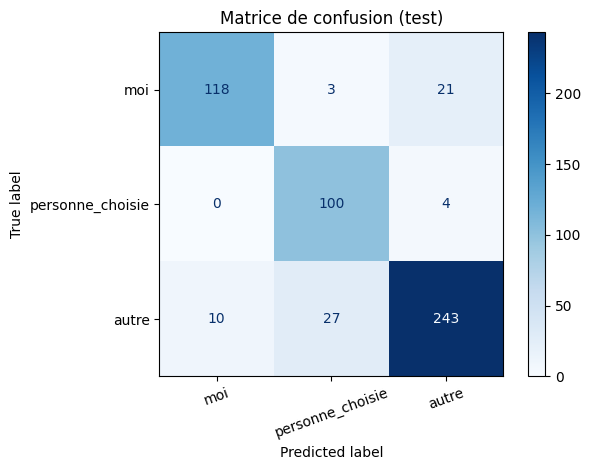

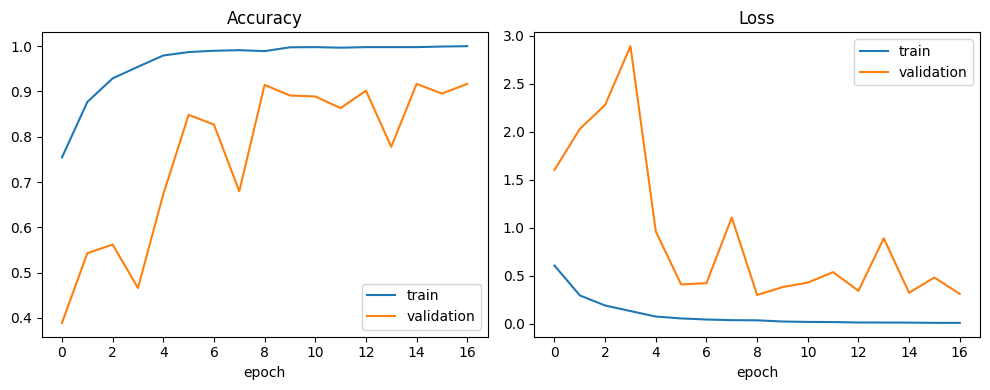

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

noms = ["moi", "personne_choisie", "autre"]

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"✅ Accuracy sur le test : {test_acc*100:.2f}%  |  loss : {test_loss:.4f}\n")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=noms, digits=3))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=noms, cmap="Blues", xticks_rotation=20
)
plt.title("Matrice de confusion (test)")
plt.tight_layout()
plt.savefig("/content/matrice_confusion.png", dpi=150)
plt.show()

# Courbes d'apprentissage
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout()
plt.savefig("/content/courbes.png", dpi=150)
plt.show()

In [26]:
import json
import numpy as np
import librosa
import tensorflow as tf

SR, SEG, N_MFCC = 16000, 2.0, 40
model = tf.keras.models.load_model("/content/modele_locuteur.keras")

def charger(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    intervalles = librosa.effects.split(y, top_db=30)
    if len(intervalles) == 0:
        return y
    return np.concatenate([y[a:b] for a, b in intervalles])

def segments(y, hop_s):
    L, H = int(SEG * SR), int(hop_s * SR)
    return [y[i:i + L] for i in range(0, len(y) - L + 1, H)]

def features(seg):
    m = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC)
    m = (m - m.mean(axis=1, keepdims=True)) / (m.std(axis=1, keepdims=True) + 1e-8)
    return m.astype(np.float32)

# --- On LIT les fichiers de test (plus de recalcul) ---
with open("/content/splits.json") as f:
    splits = json.load(f)
tests = [(p, c) for p, c in splits["test"]]
Y = np.array([c for _, c in tests])
print("Fichiers de test par classe [moi, personne_choisie, autre] :", np.bincount(Y))

# --- Contrôle : on doit retrouver 142 et 104 segments (pas 0.25 s) ---
for c, nom, attendu in [(0, "moi", 142), (1, "personne_choisie", 104)]:
    n = sum(len(segments(charger(p), 0.25)) for p, cl in tests if cl == c)
    print(f"Contrôle segments test {nom} = {n} (attendu {attendu})")

def proba_fichier(path, hop_s=1.0):
    y = charger(path)
    segs = segments(y, hop_s)
    if len(segs) == 0:
        L = int(SEG * SR)
        segs = [np.pad(y, (0, max(0, L - len(y))))[:L]]
    X = np.array([features(s) for s in segs])[..., np.newaxis]
    return model.predict(X, verbose=0).mean(axis=0)

print(f"⏳ Évaluation de {len(tests)} fichiers (1 à 3 minutes)...")
P = np.array([proba_fichier(p) for p, _ in tests])

print("\nseuil | accuracy | faux acceptés | faux rejetés | confusion moi<->perso")
pred, conf = P.argmax(axis=1), P.max(axis=1)
for seuil in [0.50, 0.60, 0.70, 0.80, 0.90]:
    final = np.where((pred < 2) & (conf < seuil), 2, pred)
    acc = (final == Y).mean()
    fa = ((Y == 2) & (final < 2)).sum() / (Y == 2).sum()
    fr = ((Y < 2) & (final == 2)).sum() / (Y < 2).sum()
    cc = ((Y < 2) & (final < 2) & (final != Y)).sum()
    print(f"{seuil:.2f}  | {acc*100:6.2f}% | {fa*100:6.2f}%      | {fr*100:6.2f}%     | {cc}")

Fichiers de test par classe [moi, personne_choisie, autre] : [ 15  13 280]
Contrôle segments test moi = 142 (attendu 142)
Contrôle segments test personne_choisie = 104 (attendu 104)
⏳ Évaluation de 308 fichiers (1 à 3 minutes)...

seuil | accuracy | faux acceptés | faux rejetés | confusion moi<->perso
0.50  |  91.88% |   8.21%      |   7.14%     | 0
0.60  |  93.51% |   6.43%      |   7.14%     | 0
0.70  |  93.83% |   5.00%      |  17.86%     | 0
0.80  |  94.16% |   4.29%      |  21.43%     | 0
0.90  |  93.83% |   3.93%      |  28.57%     | 0


In [27]:
%%writefile /content/predict.py
"""Reconnaissance du locuteur : moi / personne_choisie / autre.

Usage :
    python predict.py audio.wav
    python predict.py audio.wav --seuil 0.70 --modele model/modele_locuteur.keras
"""
import argparse
import numpy as np
import librosa
import tensorflow as tf

SR, SEG, N_MFCC = 16000, 2.0, 40
CLASSES = ["moi", "personne_choisie", "autre"]


def charger(path):
    """Charge l'audio en 16 kHz mono et supprime les silences."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    intervalles = librosa.effects.split(y, top_db=30)
    if len(intervalles) == 0:
        return y
    return np.concatenate([y[a:b] for a, b in intervalles])


def segments(y, hop_s):
    L, H = int(SEG * SR), int(hop_s * SR)
    return [y[i:i + L] for i in range(0, len(y) - L + 1, H)]


def features(seg):
    """40 MFCC, normalisés par coefficient sur le segment."""
    m = librosa.feature.mfcc(y=seg, sr=SR, n_mfcc=N_MFCC)
    m = (m - m.mean(axis=1, keepdims=True)) / (m.std(axis=1, keepdims=True) + 1e-8)
    return m.astype(np.float32)


def predire(model, path, seuil=0.70, hop_s=1.0):
    y = charger(path)
    segs = segments(y, hop_s)
    if len(segs) == 0:  # audio plus court que 2 s : on complète avec des zéros
        L = int(SEG * SR)
        segs = [np.pad(y, (0, max(0, L - len(y))))[:L]]
    X = np.array([features(s) for s in segs])[..., np.newaxis]
    proba = model.predict(X, verbose=0).mean(axis=0)
    idx = int(proba.argmax())
    confiance = float(proba[idx])
    if idx < 2 and confiance < seuil:   # pas assez sûr : refusé
        idx = 2
    ouvert = idx < 2
    return CLASSES[idx], confiance, proba, ouvert


if __name__ == "__main__":
    p = argparse.ArgumentParser(description="Reconnaissance du locuteur")
    p.add_argument("audio", help="fichier audio (wav, flac, mp3...)")
    p.add_argument("--modele", default="model/modele_locuteur.keras")
    p.add_argument("--seuil", type=float, default=0.70)
    a = p.parse_args()

    model = tf.keras.models.load_model(a.modele)
    classe, conf, proba, ouvert = predire(model, a.audio, a.seuil)

    print(f"Locuteur reconnu : {classe} (confiance {conf:.2f})")
    for nom, pr in zip(CLASSES, proba):
        print(f"  {nom:18s} {pr:.3f}")
    print("Résultat : OUVERT" if ouvert else "Résultat : REFUSÉ")

Overwriting /content/predict.py


In [28]:
import os, shutil
from google.colab import files

ACC_SEGMENTS = 87.64

REPO = "/content/reconnaissance-locuteur"
shutil.rmtree(REPO, ignore_errors=True)
os.makedirs(f"{REPO}/model")
os.makedirs(f"{REPO}/resultats")

# --- Fichiers du projet ---
shutil.copy("/content/modele_locuteur.keras", f"{REPO}/model/")
shutil.copy("/content/predict.py", REPO)
for img in ["matrice_confusion.png", "courbes.png"]:
    if os.path.exists(f"/content/{img}"):
        shutil.copy(f"/content/{img}", f"{REPO}/resultats/")

# --- requirements.txt ---
with open(f"{REPO}/requirements.txt", "w") as f:
    f.write("tensorflow\nlibrosa\nnumpy\nsoundfile\ndatasets\nscikit-learn\nmatplotlib\n")

# --- .gitignore ---
with open(f"{REPO}/.gitignore", "w") as f:
    f.write("dataset_v2/\n*.npz\n__pycache__/\n.ipynb_checkpoints/\n")

# --- README.md ---
readme = f"""# Reconnaissance du locuteur

Réseau de neurones (CNN sur MFCC) qui identifie **qui parle** parmi 3 classes :
`moi`, `personne_choisie`, `autre`. Le verrou s'ouvre pour les deux premières classes
et reste fermé pour `autre`.

## Dataset
Dataset public **LibriSpeech (dev-clean)**, téléchargé automatiquement par le notebook
(il n'est pas dans ce dépôt).

- `moi` : locuteur 2277 du dataset
- `personne_choisie` : locuteur 2035 du dataset
- `autre` : les 38 autres locuteurs

Séparation train / validation / test **sans fuite de données** : par fichier pour les deux
locuteurs ciblés, par locuteur pour `autre` (le test contient des voix jamais entendues).

## Traitement du signal
Audio 16 kHz mono, suppression des silences, segments de 2 s, 40 MFCC normalisés par segment.

## Modèle
CNN : 3 blocs Conv2D + BatchNormalization, GlobalAveragePooling, Dropout, Dense(3, softmax).
Poids de classes pour le déséquilibre, early stopping.

## Résultats
- Test par segment de 2 s : accuracy **{ACC_SEGMENTS} %** (voir `resultats/`)
- Test par fichier entier, seuil de confiance 0.70 : faux acceptés 5,0 %, faux rejetés 17,9 %,
  aucune confusion entre `moi` et `personne_choisie`

## Utilisation
    pip install -r requirements.txt
    python predict.py audio.wav
    python predict.py audio.wav --seuil 0.70

## Limites
- Seulement 2 locuteurs ciblés et 28 fichiers de test pour ces classes : les pourcentages
  par classe cible sont peu précis.
- 5 % de faux acceptés : insuffisant pour un vrai système de sécurité.
- Le modèle reconnaît les locuteurs d'entraînement ; il faudrait réentraîner pour une autre personne.
"""
with open(f"{REPO}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# --- Zip + téléchargement ---
shutil.make_archive("/content/reconnaissance-locuteur", "zip", REPO)
print("✅ Dépôt préparé :")
for racine, _, fichiers in os.walk(REPO):
    for nom in fichiers:
        print("  ", os.path.relpath(os.path.join(racine, nom), REPO))
files.download("/content/reconnaissance-locuteur.zip")

✅ Dépôt préparé :
   predict.py
   .gitignore
   README.md
   requirements.txt
   resultats/courbes.png
   resultats/matrice_confusion.png
   model/modele_locuteur.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
from google.colab import files
files.download("/content/reconnaissance-locuteur.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import json
with open("/content/splits.json") as f:
    splits = json.load(f)

for c, nom in enumerate(["moi", "personne_choisie", "autre"]):
    chemin = next(p for p, cl in splits["test"] if cl == c)
    print(f"\n=== Fichier de test de la classe '{nom}' ===")
    !python /content/predict.py {chemin} --modele /content/modele_locuteur.keras --seuil 0.70 2>/dev/null


=== Fichier de test de la classe 'moi' ===
Locuteur reconnu : moi (confiance 0.83)
  moi                0.828
  personne_choisie   0.000
  autre              0.172
Résultat : OUVERT

=== Fichier de test de la classe 'personne_choisie' ===
Locuteur reconnu : personne_choisie (confiance 1.00)
  moi                0.000
  personne_choisie   1.000
  autre              0.000
Résultat : OUVERT

=== Fichier de test de la classe 'autre' ===
Locuteur reconnu : autre (confiance 0.99)
  moi                0.013
  personne_choisie   0.000
  autre              0.987
Résultat : REFUSÉ
